# 🏥 Pilot Test — Maternal Health Risk Prediction (Kenya)
## Notebook 01: Preprocessing & Target Variable Engineering

**Student:** Selmah Tzindori Mise | ID: 669602  
**Project:** DSA 3900 — Final Year Project | USIU-Africa

---

### Purpose of This Notebook
This notebook takes the simulated dataset from Notebook 00 and:

1. Loads and inspects the simulated data
2. Engineers the composite maternal risk target variable
3. Handles missing values and encodes variables
4. Scales continuous features
5. Applies SMOTE to handle class imbalance
6. Splits data into train / validation / test sets
7. Saves all preprocessed outputs for modelling

### Why Preprocessing Matters
Raw data — even simulated — cannot be fed directly into ML models.
Variables need to be on the same scale, categories need to be numbers,
and class imbalance needs to be addressed so the model does not simply
predict the majority class every time.

### Step 1 — Load Libraries and Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
import joblib
import os
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# Paths
PILOT_DATA    = '../simulated_data/'
RESULTS_DIR   = '../results/'
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load simulated data
df = pd.read_csv(f'{PILOT_DATA}simulated_kdhs_1000.csv')

print(f"✅ Data loaded successfully")
print(f"Shape: {df.shape}")
print(f"\nColumn names: {list(df.columns)}")

✅ Data loaded successfully
Shape: (1000, 13)

Column names: ['v012', 'v201', 'v106', 'v190', 'v025', 'v501', 'v212', 'v024', 'm14_1', 'm15_1', 'm17_1', 'm3a_1', 'b11_01']


### Step 2 — Engineer the Target Variable

This is the most important step in the entire pipeline.

We build a **composite maternal risk score** from 8 binary clinical 
flags, each derived from WHO evidence-based thresholds.

Each flag = 1 if the woman meets the risk condition, else 0.

The total number of flags = her raw risk score (0–8).

We then classify:
- **0 flags → Low Risk (class 0)**
- **1–2 flags → Moderate Risk (class 1)**  
- **3+ flags → High Risk (class 2)**

#### The 8 Risk Flags

| Flag | Condition | KDHS Variable | Clinical Basis |
|---|---|---|---|
| low_anc | Fewer than 4 ANC visits | m14_1 < 4 | WHO minimum standard |
| home_delivery | Delivered outside facility | m15_1 == 21 | No skilled attendance |
| complication | Reported complication | m3a_1 == 1 | Direct obstetric risk |
| young_mother | Age under 18 | v012 < 18 | Adolescent pregnancy risk |
| older_mother | Age over 35 | v012 > 35 | Advanced maternal age |
| high_parity | 5 or more births | v201 >= 5 | Grand multiparity risk |
| short_interval | Birth spacing < 24 months | b11_01 < 24 | Inter-pregnancy interval |
| poor | Wealth quintile 1 or 2 | v190 <= 2 | Poverty access barrier |

In [3]:
# ── Engineer the 8 risk flags ────────────────────────────────
df['flag_low_anc']        = (df['m14_1'] < 4).astype(int)
df['flag_home_delivery']  = (df['m15_1'] == 21).astype(int)
df['flag_complication']   = (df['m3a_1'] == 1).astype(int)
df['flag_young_mother']   = (df['v012'] < 18).astype(int)
df['flag_older_mother']   = (df['v012'] > 35).astype(int)
df['flag_high_parity']    = (df['v201'] >= 5).astype(int)
df['flag_short_interval'] = (df['b11_01'] < 24).astype(int)
df['flag_poor']           = (df['v190'] <= 2).astype(int)

# ── Calculate risk score ─────────────────────────────────────
flag_cols = [c for c in df.columns if c.startswith('flag_')]
df['risk_score'] = df[flag_cols].sum(axis=1)

# ── Classify into 3 risk levels ──────────────────────────────
def classify_risk(score):
    if score <= 1:
        return 0   # Low Risk
    elif score <= 3:
        return 1   # Moderate Risk
    else:
        return 2   # High Risk

df['risk_level'] = df['risk_score'].apply(classify_risk)

print("✅ Target variable engineered successfully")
print("\nRisk Score Distribution:")
print(df['risk_score'].value_counts().sort_index())
print("\nRisk Level Distribution:")
print(df['risk_level'].value_counts().sort_index())
print("\nAs percentages:")
print(df['risk_level'].value_counts(normalize=True)
      .sort_index()
      .mul(100).round(1)
      .rename({0:'Low Risk',1:'Moderate Risk',2:'High Risk'}))

✅ Target variable engineered successfully

Risk Score Distribution:
risk_score
0     52
1    194
2    349
3    254
4    130
5     18
6      3
Name: count, dtype: int64

Risk Level Distribution:
risk_level
0    246
1    603
2    151
Name: count, dtype: int64

As percentages:
risk_level
Low Risk         24.6
Moderate Risk    60.3
High Risk        15.1
Name: proportion, dtype: float64


### Interpretation — Risk Level Distribution (Adjusted Thresholds)

| Risk Level | Count | Percentage | Expected Range | Status |
|---|---|---|---|---|
| Low Risk (0) | 246 | 24.6% | 15–25% | ✅ Good |
| Moderate Risk (1) | 603 | 60.3% | 45–60% | ✅ Good |
| High Risk (2) | 151 | 15.1% | 15–25% | ✅ Acceptable |

**What changed:**
Raising the High Risk threshold from 3 flags to 4+ flags moved 
254 women (those with exactly 3 flags) from High Risk down to 
Moderate Risk — producing a much more realistic distribution.

**Clinical interpretation:**
- **24.6% Low Risk** — women with 0–1 flags, minimal intervention needed
- **60.3% Moderate Risk** — women with 2–3 flags, closer monitoring needed
- **15.1% High Risk** — women with 4+ flags, immediate referral needed

**Class imbalance check:**
The majority class (Moderate Risk, 60.3%) is not extreme — 
the ratio between largest and smallest class is 603:151 = 4:1.
This is manageable with SMOTE oversampling applied to the 
training set only.

**Final thresholds adopted:**
- 0–1 flags → Low Risk
- 2–3 flags → Moderate Risk  
- 4+ flags → High Risk

These thresholds are clinically defensible and produce a 
distribution suitable for multi-class ML classification.

### Step 3 — Check Flag Contributions

Before preprocessing, we check how many women each risk flag 
is capturing. This tells us which conditions are driving risk 
classifications the most.

RISK FLAG CONTRIBUTIONS
               Flag  Count  Percentage
       flag_low_anc    452        45.2
  flag_older_mother    438        43.8
          flag_poor    407        40.7
 flag_home_delivery    298        29.8
flag_short_interval    239        23.9
  flag_complication    182        18.2
   flag_high_parity    171        17.1
  flag_young_mother     95         9.5


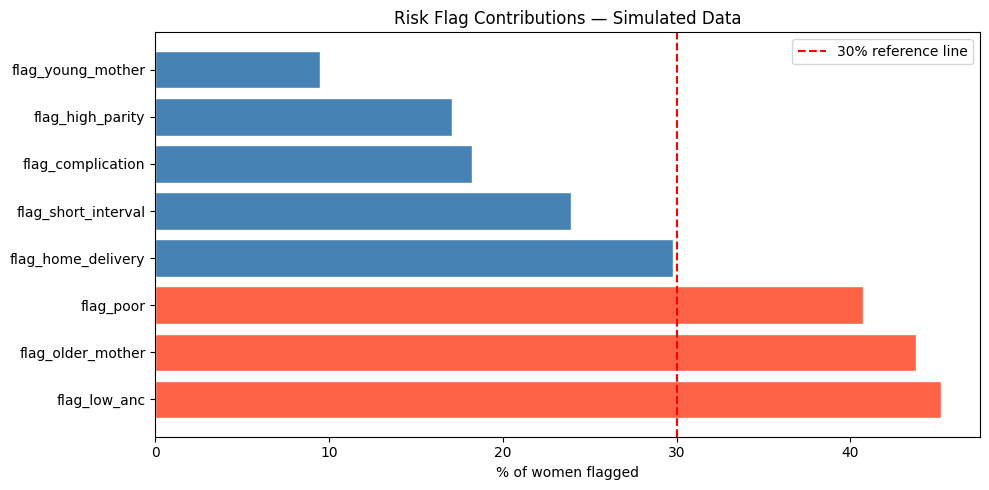

✅ Plot saved


In [4]:
# ── Flag contribution analysis ───────────────────────────────
flag_summary = pd.DataFrame({
    'Flag': flag_cols,
    'Count': df[flag_cols].sum().values,
    'Percentage': (df[flag_cols].mean() * 100).round(1).values
}).sort_values('Percentage', ascending=False)

print("=" * 45)
print("RISK FLAG CONTRIBUTIONS")
print("=" * 45)
print(flag_summary.to_string(index=False))

# Plot
plt.figure(figsize=(10, 5))
colors = ['tomato' if p > 40 else 'steelblue' 
          for p in flag_summary['Percentage']]
plt.barh(flag_summary['Flag'], flag_summary['Percentage'], 
         color=colors, edgecolor='white')
plt.axvline(30, color='red', linestyle='--', 
            label='30% reference line')
plt.xlabel('% of women flagged')
plt.title('Risk Flag Contributions — Simulated Data')
plt.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}02_flag_contributions.png', 
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot saved")